# Decision Trees: Classification and Regression

Visualize an Iris classifier and explore a regression tree. Run cells from top to bottom. Requires NumPy, Matplotlib, and scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

RANDOM_STATE = 42


## 1. Load the Iris dataset

Use all 150 flowers and two features: petal length and petal width. Targets are the three species. This is a training-data visualization; evaluating generalization requires a test set or cross-validation.

In [2]:
iris = load_iris()
X = iris.data[:, 2:]  # petal length and width
y = iris.target
print(f"Samples: {len(X)} | Features: {X.shape[1]}")


Samples: 150 | Features: 2


## 2. Train the classifier

Limit depth to two to keep the rules easy to inspect. Fix the random seed for reproducibility.

In [3]:
tree_clf = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)
tree_clf.fit(X, y)


### Inspect the tree

Nodes show feature thresholds, Gini impurity, sample counts, and class counts. A pure node has zero Gini impurity.

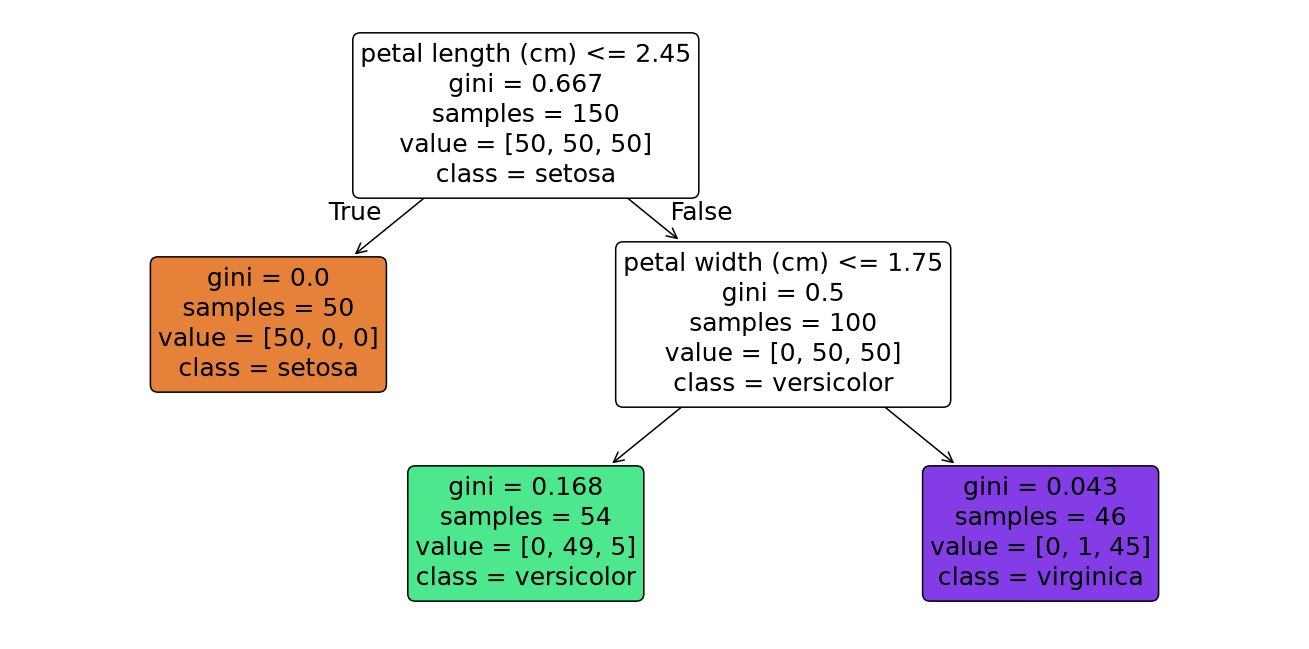

In [4]:
plt.figure(figsize=(12, 6))
plot_tree(
    tree_clf,
    feature_names=iris.feature_names[2:],
    class_names=iris.target_names,
    filled=True,
    rounded=True,
)
plt.tight_layout()
plt.show()


### Predict class probabilities

For petal length 5 cm and width 1.5 cm, probabilities are class proportions in the reached leaf. They are model estimates, not guarantees.

In [5]:
sample = np.array([[5.0, 1.5]])
probabilities = tree_clf.predict_proba(sample)[0]
for class_id, probability in zip(tree_clf.classes_, probabilities):
    print(f"{iris.target_names[class_id]}: {probability:.1%}")


setosa: 0.0%
versicolor: 90.7%
virginica: 9.3%


## 3. Full dataset and decision boundaries

Predict a dense grid to shade the classification regions. Dashed lines mark changes in predicted class. Dots show the actual species of all 150 samples; some overlap. A dot in another class's region is a training error.

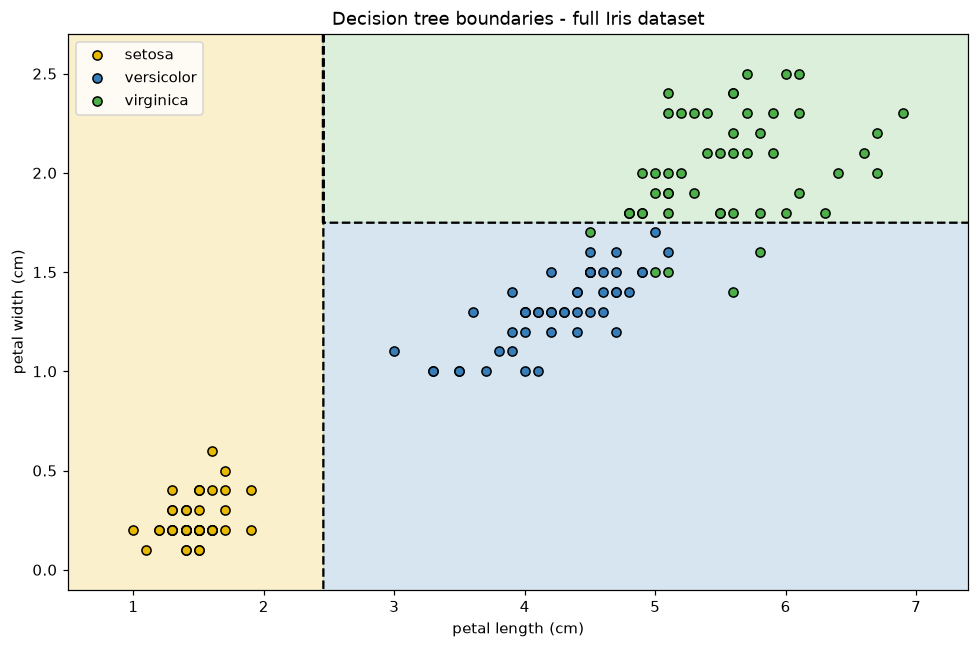

In [6]:
# Create a grid covering the full dataset
x1, x2 = np.meshgrid(
    np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 500),
    np.linspace(X[:, 1].min() - 0.2, X[:, 1].max() + 0.2, 500),
)

# Predict the class at every grid point
predictions = tree_clf.predict(
    np.c_[x1.ravel(), x2.ravel()]
).reshape(x1.shape)

colors = ["#e6b800", "#377eb8", "#4daf4a"]
cmap = ListedColormap(colors)

fig, ax = plt.subplots(figsize=(9, 6))

ax.contourf(
    x1, x2, predictions,
    levels=[-0.5, 0.5, 1.5, 2.5],
    cmap=cmap, alpha=0.2,
)
ax.contour(
    x1, x2, predictions,
    levels=[0.5, 1.5],
    colors="black", linestyles="--",
)

for class_id, class_name in enumerate(iris.target_names):
    ax.scatter(
        X[y == class_id, 0],
        X[y == class_id, 1],
        color=colors[class_id],
        edgecolors="black",
        label=class_name,
    )

ax.set(
    xlabel=iris.feature_names[2],
    ylabel=iris.feature_names[3],
    title="Decision tree boundaries - full Iris dataset",
)
ax.legend()
plt.tight_layout()
plt.show()


## 4. Regression with a continuous target

Iris species labels are categories. For regression, use a noisy quadratic relationship instead. Each regression leaf predicts the mean target of its training samples, producing a step-shaped curve.

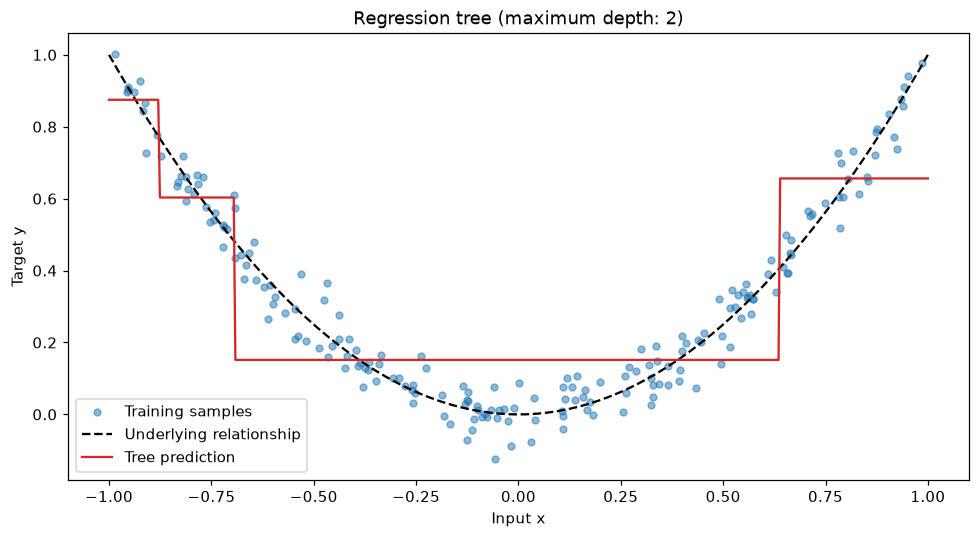

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
X_reg = np.sort(rng.uniform(-1, 1, 200)).reshape(-1, 1)
y_reg = X_reg[:, 0] ** 2 + rng.normal(0, 0.05, 200)

tree_reg = DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE)
tree_reg.fit(X_reg, y_reg)

X_curve = np.linspace(-1, 1, 500).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(X_reg[:, 0], y_reg, s=20, alpha=0.5, label="Training samples")
ax.plot(X_curve[:, 0], X_curve[:, 0] ** 2, "k--", label="Underlying relationship")
ax.plot(X_curve[:, 0], tree_reg.predict(X_curve), color="tab:red", label="Tree prediction")
ax.set(xlabel="Input x", ylabel="Target y", title="Regression tree (maximum depth: 2)")
ax.legend()
fig.tight_layout()
plt.show()


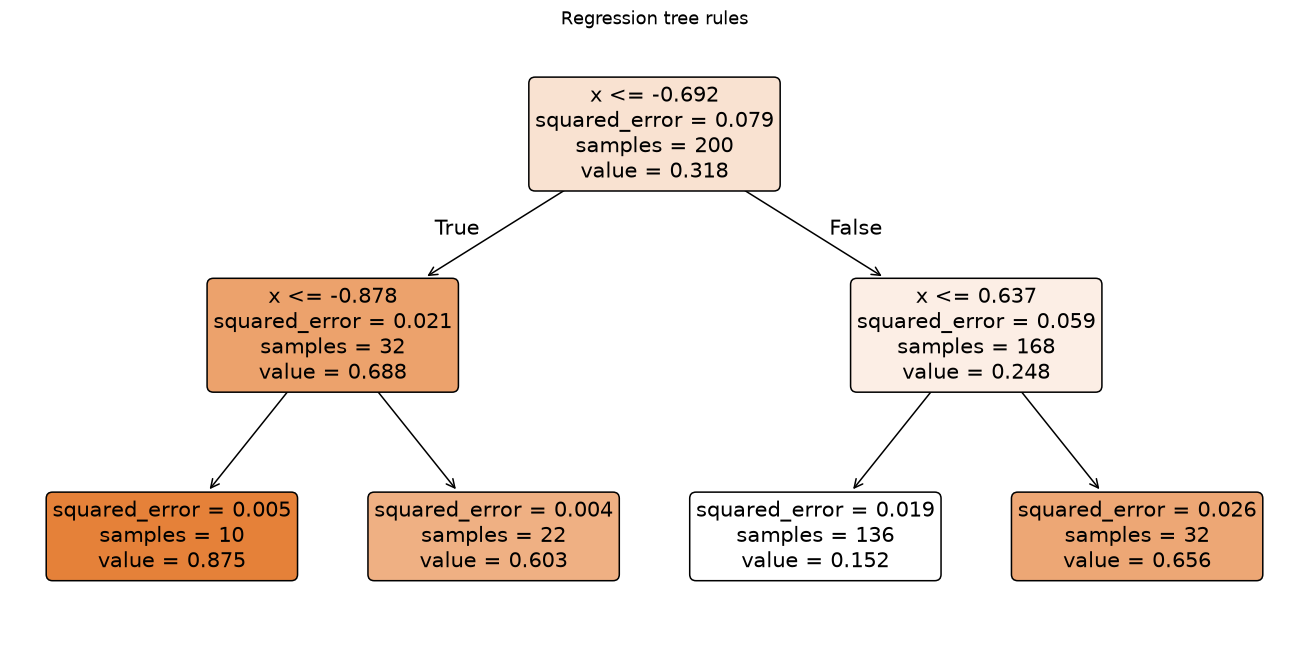

In [8]:
fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(tree_reg, feature_names=["x"], filled=True, rounded=True, ax=ax)
ax.set_title("Regression tree rules")
fig.tight_layout()
plt.show()


## Key observations

- Classification trees partition features into regions with one predicted class per region.
- Axis-aligned splits create horizontal and vertical boundaries.
- Regression trees predict a constant within each leaf.
- Limiting depth controls complexity; separate evaluation is needed to assess generalization.